# Assignment 3: Simulate step response

**Author:** Lino Kaiser.

The next tasks for this notebook are as follows:

- Determine the time step and the settling time.
- Give the input vector $u$.
- Integrate the differential equations in time.
- Plot the results.
- Discuss the results.

In [48]:
%run 02_steady_state2.ipynb

air_temperatures = [3.58955938 3.39932847] °C
air_temperatures = [3.58955938 3.39932847] °C


We can start by determining the maximum time step that we could take. As we know, this can be calculated using the eigenvalues of the state matrix $A_s$ in s⁻¹.

First, calculate the eigenvalues of $A_s$. Next, we need to convert them into time constants in seconds. The time step $\Delta t$ has to be smaller than twice the smallest time constant.

Lastly, the source calculates the settling time in seconds as follows. Here, $λ$ denotes the eigenvalues.

```python
t_settle = 4 * max(-1 / λ)

print(f'Settling time: {t_settle:.2f} s = {t_settle / 3600:.2f} h')
```

Let's reuse that in our code.

In [49]:
# Step 1. Calculate the eigenvalues of As in s⁻¹.
eigenvalues = np.linalg.eigvals(As)

# Step 2. Convert them into time constants in seconds.
time_constants = -1 / eigenvalues

# Step 3. The time step must be smaller than twice the smallest time constant.
time_constants_min = np.min (time_constants)

# Step 4. Calculate the upper limit for the time step in seconds.

step_size = 2 * time_constants_min

print ("step size =", step_size)

# Step 5. Calculate the settling time in seconds.

settling_time = 4 * max(-1 / eigenvalues)
print(f'Settling time: {settling_time:.2f} s = {settling_time / 86400:.2f} days')

step size = 318.92272103121076
Settling time: 412799.25 s = 4.78 days


The maximum time step for explicit Euler and the settling time are printed above. I will use a time step of 60 s.

Next is the input vector $u$. For this scenario, we will reuse the vector we already defined. It contains temperatures in °C.

The source integrates the step response as follows.

```python
# duration: next multiple of 3600 s that is larger than t_settle
duration = np.ceil(t_settle / 3600) * 3600
n = int(np.floor(duration / dt))    # number of time steps
t = np.arange(0, n * dt, dt)        # time vector for n time steps

print(f'Duration = {duration} s')
print(f'Number of time steps = {n}')
# pd.DataFrame(t, columns=['time'])

# initial conditions
n_s = As.shape[0]                      # number of state variables
θ_exp = np.zeros([n_s, t.shape[0]])    # explicit Euler in time t
θ_imp = np.zeros([n_s, t.shape[0]])    # implicit Euler in time t

# time integration
I = np.eye(n_s)                        # identity matrix

for k in range(n - 1):
    θ_exp[:, k + 1] = (I + dt * As) @ θ_exp[:, k]\
        + dt * Bs @ u[k, :]
    θ_imp[:, k + 1] = np.linalg.inv(I - dt * As) @ (θ_imp[:, k]\
        + dt * Bs @ u[k, :])

# outputs
y_exp = Cs @ θ_exp + Ds @  u.T
y_imp = Cs @ θ_imp + Ds @  u.T
```

I will reuse that code.

In [50]:
duration = np.ceil(settling_time / 3600) * 3600
time_step_duration = 60  # s
number_of_time_steps = int(np.floor(duration / time_step_duration))
t = np.arange(0, number_of_time_steps * time_step_duration, time_step_duration)

u_steps = np.tile(u, (number_of_time_steps, 1)) # Repeat the input vector once per time step.

print(f'Duration = {duration} s')
print(f'Number of time steps = {number_of_time_steps}')

Duration = 414000.0 s
Number of time steps = 6900


Next, we need to integrate the differential equations in time.

In [51]:
n_s = As.shape[0]                     
θ_exp = np.zeros([n_s, t.shape[0]])    

# Time integration
I = np.eye(n_s)                        # Identity matrix

for k in range(number_of_time_steps - 1):
    θ_exp[:, k + 1] = (I + time_step_duration * As) @ θ_exp[:, k]\
        + time_step_duration * Bs @ u_steps[k, :] 

y_exp = Cs @ θ_exp + Ds @  u_steps.T

Then we need to plot the results.

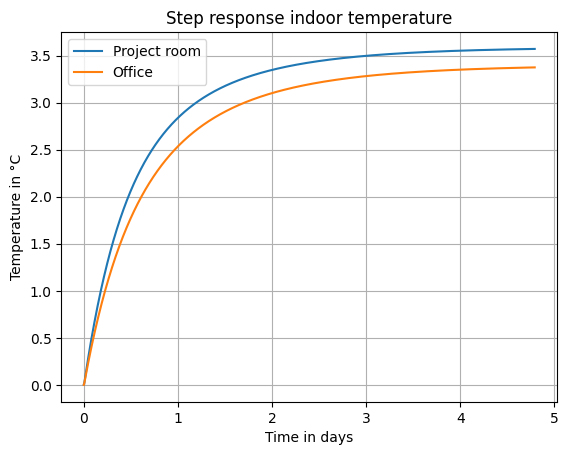

In [52]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(t / 86400, y_exp.T)
ax.set(xlabel='Time in days',
       ylabel='Temperature in °C',
       title='Step response indoor temperature')
ax.legend(["Project room", "Office"])
ax.grid()
plt.show()

We use explicit Euler with a time step of 60 s, which is well below the stability limit. We use 60 s because we are mostly interested in comfort.

Everything looks correct.

**Sources:** Christian Ghiaus, [dm4bem](https://github.com/cghiaus/dm4bem).